In [7]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn 

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("transactions_TP2.csv")

display(df.head())

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nTypes des variables :")
print(df.dtypes) 

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


Nombre de lignes : 3045
Nombre de colonnes : 12

Types des variables :
id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object


In [9]:
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().mean() * 100)
missing_table = pd.DataFrame({
    'Nombre de valeurs manquantes': missing_count,
    'Pourcentage (%)': missing_percentage
})
missing_table = missing_table.sort_values(
    by='Pourcentage (%)',
    ascending=False
)
display(missing_table.round(2)) 

,Nombre de valeurs manquantes,Pourcentage (%)
canal,159,5.22
anciennete_mois,137,4.50
appareil,122,4.01
montant_dh,110,3.61
region,103,3.38
nb_ops_24h,53,1.74
id_operation,0,0.00
id_client,0,0.00
heure,0,0.00
international,0,0.00


In [10]:
nb_doublons = df.duplicated(subset=['id_operation']).sum()
print("Nombre de doublons :", nb_doublons)

df = df.drop_duplicates(
    subset=['id_operation'],
    keep='first'
)
print("Nombre de lignes restantes :", df.shape[0])
print("Nombre de doublons restants :", df.duplicated(subset=['id_operation']).sum())

Nombre de doublons : 45
Nombre de lignes restantes : 3000
Nombre de doublons restants : 0


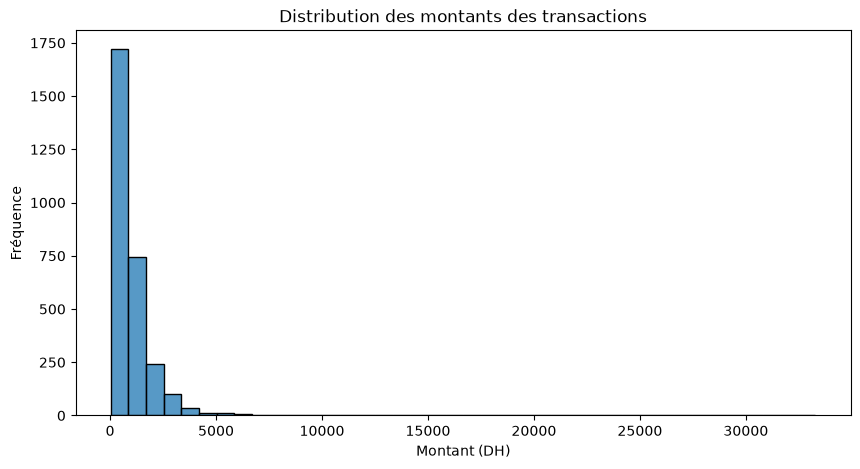

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot( data=df, x='montant_dh', bins=40, edgecolor='black')

plt.title("Distribution des montants des transactions")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

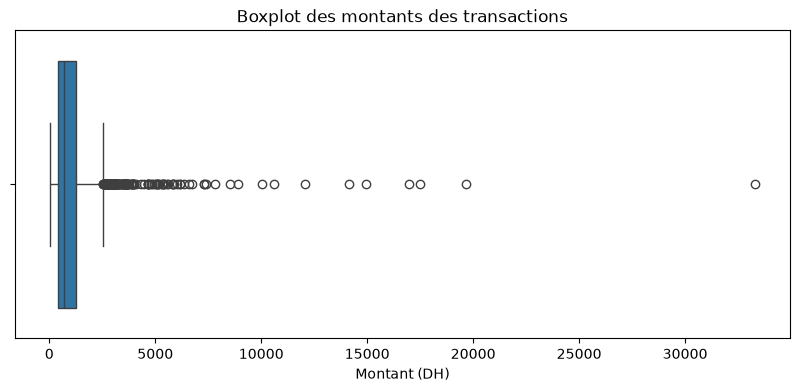

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['montant_dh'])
plt.title("Boxplot des montants des transactions")
plt.xlabel("Montant (DH)")
plt.show()

In [13]:
montants_extremes = df.nlargest(10, 'montant_dh')
display( montants_extremes[['id_operation', 'montant_dh', 'fraude']])

,id_operation,montant_dh,fraude
2660,OP02851,33281.23,0
539,OP02169,19658.42,0
1775,OP00087,17496.64,0
1557,OP02211,16962.99,0
2556,OP02832,14951.95,0
65,OP02462,14135.85,0
1010,OP01376,12046.21,0
32,OP00591,10598.93,0
1313,OP02983,10028.37,0
2145,OP00127,8910.60,0


In [14]:
Q1 = df['montant_dh'].quantile(0.25)
Q3 = df['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

outliers = df[
    (df['montant_dh'] < limite_inf) | (df['montant_dh'] > limite_sup)
]
print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Limite inférieure :", limite_inf)
print("Limite supérieure :", limite_sup)
print("Nombre de valeurs extrêmes :", len(outliers))

Q1 : 389.53
Q3 : 1249.48
IQR : 859.95
Limite inférieure : -900.3950000000002
Limite supérieure : 2539.405
Nombre de valeurs extrêmes : 184


In [15]:
class_counts = df['fraude'].value_counts().sort_index()
print("Nombre de transactions par classe :")
print(class_counts)

class_percentages = df['fraude'].value_counts(normalize=True).sort_index() * 100
print("\nPourcentage par classe :")
print(class_percentages.round(2))

Nombre de transactions par classe :
fraude
0    2742
1     258
Name: count, dtype: int64

Pourcentage par classe :
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


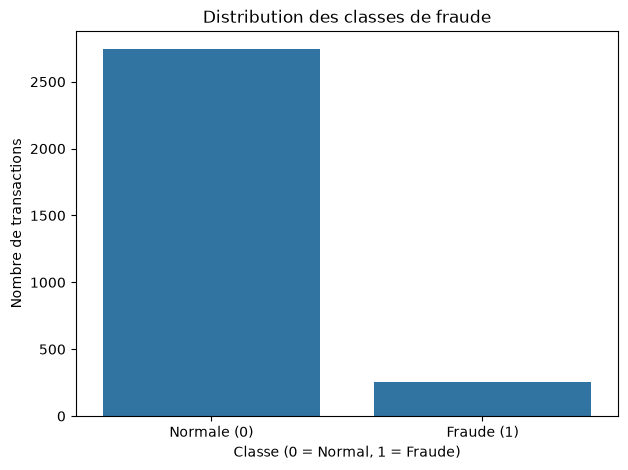

In [16]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='fraude')
plt.title("Distribution des classes de fraude")
plt.xlabel("Classe (0 = Normal, 1 = Fraude)")
plt.ylabel("Nombre de transactions")
plt.xticks([0, 1], ['Normale (0)', 'Fraude (1)'])
plt.show()

In [17]:
colonnes_a_exclure = ['id_operation', 'id_client', 'resultat_enquete']
print("Colonnes à exclure :")
print(colonnes_a_exclure)

Colonnes à exclure :
['id_operation', 'id_client', 'resultat_enquete']


In [18]:
y = df['fraude']
X = df.drop(columns=['id_operation','id_client','resultat_enquete','fraude'])

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())
print("\nVariable cible :")
print(y.name)

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)

Variables explicatives :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']

Variable cible :
fraude


In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)

Dimensions de X_train : (2400, 8)
Dimensions de X_test : (600, 8)
Dimensions de y_train : (2400,)
Dimensions de y_test : (600,)


In [20]:
print("Proportions dans Train :")
print((y_train.value_counts(normalize=True) * 100).round(2))
print("\nProportions dans Test :")
print((y_test.value_counts(normalize=True) * 100).round(2))

Proportions dans Train :
fraude
0    91.42
1     8.58
Name: proportion, dtype: float64

Proportions dans Test :
fraude
0    91.33
1     8.67
Name: proportion, dtype: float64


In [22]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()

print("Variables numériques :")
print(num_cols)
print("\nVariables catégorielles :")
print(cat_cols)

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']

Variables catégorielles :
['canal', 'appareil', 'region', 'international']


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
X_train_num = num_pipe.fit_transform(X_train[num_cols])
X_test_num = num_pipe.transform(X_test[num_cols])

print("Train :", X_train_num.shape)
print("Test :", X_test_num.shape)

Train : (2400, 4)
Test : (600, 4)


In [24]:
imputer = num_pipe.named_steps['imputer']
scaler = num_pipe.named_steps['scaler']

print("Médianes calculées :")
print(imputer.statistics_)

print("\nMoyennes calculées :")
print(scaler.mean_)

print("\nÉcarts-types calculés :")
print(scaler.scale_)

Médianes calculées :
[710.79  87.     3.    11.  ]

Moyennes calculées :
[1020.672925     87.48333333    2.72083333   11.47      ]

Écarts-types calculés :
[1327.6254132    49.48592112    1.64607593    6.99546996]


In [25]:
from sklearn.preprocessing import OneHotEncoder
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
X_train_cat = cat_pipe.fit_transform(X_train[cat_cols])
X_test_cat = cat_pipe.transform(X_test[cat_cols])

print("Train :", X_train_cat.shape)
print("Test :", X_test_cat.shape)

Train : (2400, 14)
Test : (600, 14)


In [26]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    ('numeric', num_pipe, num_cols),
    ('categorical', cat_pipe, cat_cols)
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Dimensions Train :", X_train_prepared.shape)
print("Dimensions Test :", X_test_prepared.shape)

Dimensions Train : (2400, 18)
Dimensions Test : (600, 18)


In [27]:
from sklearn.preprocessing import RobustScaler
num_pipe_robust = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
X_train_robust = num_pipe_robust.fit_transform(X_train[num_cols])
X_test_robust = num_pipe_robust.transform(X_test[num_cols])

print("Train :", X_train_robust.shape)
print("Test :", X_test_robust.shape)

Train : (2400, 4)
Test : (600, 4)


In [28]:
valeurs = pd.DataFrame({
    'montant_dh': [500, 1000, 1500, 33281.23]
})
imputer_amount = SimpleImputer(strategy='median')
train_amount = imputer_amount.fit_transform(X_train[['montant_dh']])
valeurs_imputees = imputer_amount.transform(valeurs)

standard = StandardScaler()
standard.fit(train_amount)

robust = RobustScaler()
robust.fit(train_amount)

valeurs['StandardScaler'] = standard.transform(valeurs_imputees).ravel()
valeurs['RobustScaler'] = robust.transform(valeurs_imputees).ravel()

display(valeurs.round(3))

,montant_dh,StandardScaler,RobustScaler
0,500.00,-0.392,-0.258
1,1000.00,-0.016,0.354
2,1500.00,0.361,0.967
3,33281.23,24.299,39.893


In [29]:
Q1 = X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


In [30]:
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)

outliers = X_train[(X_train['montant_dh'] < borne_inf) | (X_train['montant_dh'] > borne_sup)]
print("Nombre de montants extrêmes :", len(outliers))
print(outliers[['montant_dh']].head(10))

Borne inférieure : -892.0787499999999
Borne supérieure : 2535.05125
Nombre de montants extrêmes : 146
      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99
2088     2645.74
1105     6733.98
1074     2535.89
396      3002.07
329      5021.72


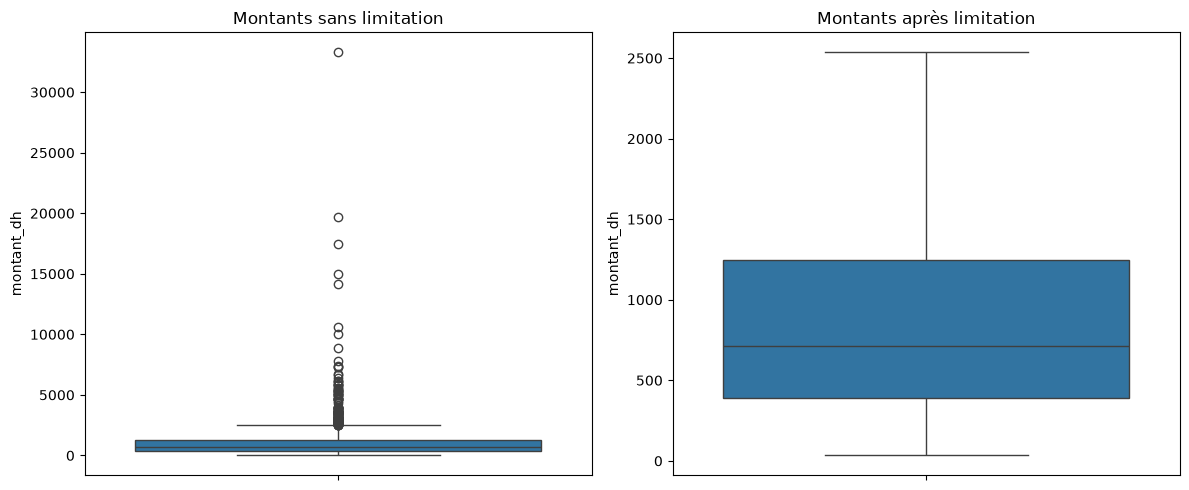

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

X_train_clipped = X_train.copy()
X_train_clipped['montant_dh'] = X_train_clipped['montant_dh'].clip(
    lower=borne_inf,
    upper=borne_sup
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=X_train['montant_dh'], ax=axes[0])
axes[0].set_title("Montants sans limitation")

sns.boxplot(y=X_train_clipped['montant_dh'], ax=axes[1])
axes[1].set_title("Montants après limitation")

plt.tight_layout()
plt.show()

In [32]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

train_montant = X_train[['montant_dh']]
test_montant = X_test[['montant_dh']]

scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

train_minmax = scaler_minmax.fit_transform(train_montant)
test_minmax = scaler_minmax.transform(test_montant)

train_standard = scaler_standard.fit_transform(train_montant)
test_standard = scaler_standard.transform(test_montant)

train_robust = scaler_robust.fit_transform(train_montant)
test_robust = scaler_robust.transform(test_montant)

print("Transformations terminées.")

Transformations terminées.


In [33]:
print("MinMaxScaler :")
print("Train :", train_minmax[:5].flatten())
print("Test :", test_minmax[:5].flatten())

print("\nStandardScaler :")
print("Train :", train_standard[:5].flatten())
print("Test :", test_standard[:5].flatten())

print("\nRobustScaler :")
print("Train :", train_robust[:5].flatten())
print("Test :", test_robust[:5].flatten())

MinMaxScaler :
Train : [0.0115242  0.01493767 0.01327906 0.07464832 0.01077852]
Test : [0.02283333 0.03334204 0.00669849 0.00936657 0.01248164]

StandardScaler :
Train : [-0.45360714 -0.3696258  -0.41043238  1.09943348 -0.47195308]
Test : [-0.17536899  0.08317633 -0.57233403 -0.50669123 -0.43005122]

RobustScaler :
Train : [-0.33994625 -0.20749724 -0.27185429  2.10939182 -0.36888008]
Test : [ 0.0988699   0.50662799 -0.52719331 -0.42366645 -0.30279563]


In [35]:
import pandas as pd
montants = pd.DataFrame({
    'montant_initial': [
        X_train['montant_dh'].quantile(0.25),
        X_train['montant_dh'].median(),
        X_train['montant_dh'].quantile(0.75),
        X_train['montant_dh'].max()
    ]
})
montants_a_transformer = montants[['montant_initial']].rename(columns={'montant_initial': 'montant_dh'})
montants['MinMax'] = scaler_minmax.transform(montants_a_transformer).flatten()
montants['StandardScaler'] = scaler_standard.transform(montants_a_transformer).flatten()
montants['RobustScaler'] = scaler_robust.transform(montants_a_transformer).flatten()

print(montants.round(3))

   montant_initial  MinMax  StandardScaler  RobustScaler
0          393.095   0.011          -0.473        -0.371
1          710.790   0.020          -0.238         0.000
2         1249.878   0.037           0.161         0.629
3        33281.230   1.000          23.866        38.015


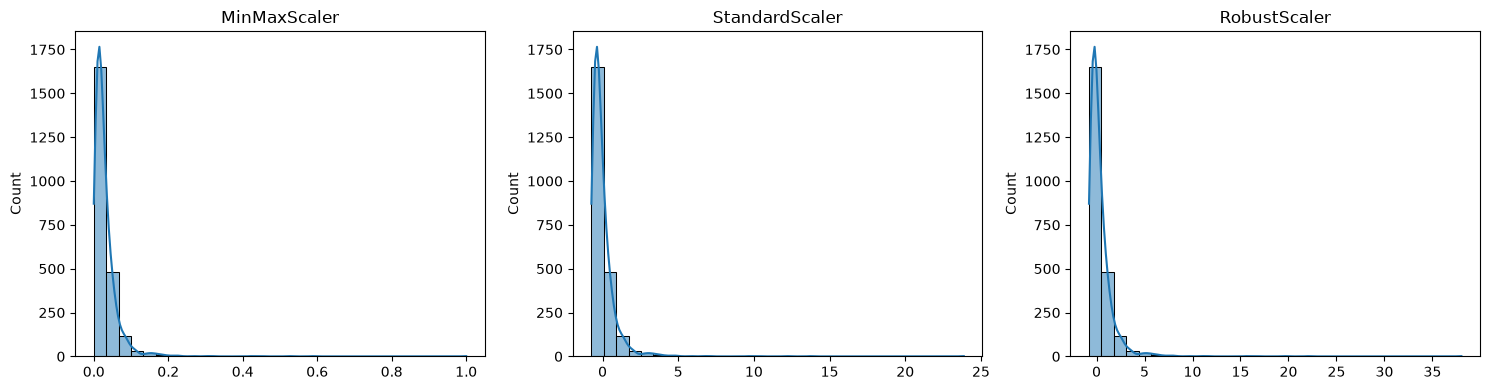

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(train_minmax.flatten(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("MinMaxScaler")
sns.histplot(train_standard.flatten(), bins=30, kde=True, ax=axes[1])
axes[1].set_title("StandardScaler")
sns.histplot(train_robust.flatten(), bins=30, kde=True, ax=axes[2])
axes[2].set_title("RobustScaler")

plt.tight_layout()
plt.show()

In [38]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

train_exemple = np.array([[100], [500], [1000]])
nouvelle_transaction = np.array([[1200]])

scaler = MinMaxScaler()
scaler.fit(train_exemple)

resultat = scaler.transform(nouvelle_transaction)

print("Montant initial :", nouvelle_transaction[0, 0], "DH")
print("Montant transformé :", resultat[0, 0])

Montant initial : 1200 DH
Montant transformé : 1.222222222222222


In [39]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64


In [40]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

print("Avant le sur-échantillonnage :")
print(y_train.value_counts())
print("\nAprès le sur-échantillonnage :")
print(y_train_over.value_counts())

Avant le sur-échantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64

Après le sur-échantillonnage :
fraude
0    2194
1    2194
Name: count, dtype: int64


In [41]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

print("Avant le sous-échantillonnage :")
print(y_train.value_counts())
print("\nAprès le sous-échantillonnage :")
print(y_train_under.value_counts())

Avant le sous-échantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64

Après le sous-échantillonnage :
fraude
0    206
1    206
Name: count, dtype: int64


In [42]:
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer

X_train_2 = X_train[['montant_dh', 'anciennete_mois']]

imputer = SimpleImputer(strategy='median')
X_train_2 = imputer.fit_transform(X_train_2)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_2, y_train)

print("Avant SMOTE :")
print(y_train.value_counts())
print("\nAprès SMOTE :")
print(y_train_smote.value_counts())

Avant SMOTE :
fraude
0    2194
1     206
Name: count, dtype: int64

Après SMOTE :
fraude
0    2194
1    2194
Name: count, dtype: int64


In [43]:
comparaison = pd.DataFrame({
    'Avant': y_train.value_counts().sort_index(),
    'RandomOverSampler': y_train_over.value_counts().sort_index(),
    'RandomUnderSampler': y_train_under.value_counts().sort_index(),
    'SMOTE': y_train_smote.value_counts().sort_index()
})
print(comparaison)

        Avant  RandomOverSampler  RandomUnderSampler  SMOTE
fraude                                                     
0        2194               2194                 206   2194
1         206               2194                 206   2194


In [44]:
print("Répartition des classes dans le test :")
print(y_test.value_counts())

Répartition des classes dans le test :
fraude
0    548
1     52
Name: count, dtype: int64


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_pipe_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
cat_pipe_final = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor_final = ColumnTransformer([
    ('numeric', num_pipe_final, num_cols),
    ('categorical', cat_pipe_final, cat_cols)
])
print("Préprocesseur final créé avec succès.")

Préprocesseur final créé avec succès.


In [46]:
X_train_final = preprocessor_final.fit_transform(X_train)
X_test_final = preprocessor_final.transform(X_test)

print("Dimensions Train :", X_train_final.shape)
print("Dimensions Test :", X_test_final.shape)

Dimensions Train : (2400, 18)
Dimensions Test : (600, 18)


In [47]:
import numpy as np
from scipy import sparse

print("Nombre de colonnes Train :", X_train_final.shape[1])
print("Nombre de colonnes Test :", X_test_final.shape[1])

if sparse.issparse(X_train_final):
    missing_train = np.isnan(X_train_final.data).any()
else:
    missing_train = np.isnan(X_train_final).any()

if sparse.issparse(X_test_final):
    missing_test = np.isnan(X_test_final.data).any()
else:
    missing_test = np.isnan(X_test_final).any()

print("Valeurs manquantes dans Train :", missing_train)
print("Valeurs manquantes dans Test :", missing_test)

Nombre de colonnes Train : 18
Nombre de colonnes Test : 18
Valeurs manquantes dans Train : False
Valeurs manquantes dans Test : False


In [48]:
nouvelle_ligne = X_test.iloc[[0]].copy()
nouvelle_ligne['canal'] = 'canal_inconnu'

nouvelle_ligne_transformee = preprocessor_final.transform(nouvelle_ligne)
print("Transformation réussie.")
print("Dimensions :", nouvelle_ligne_transformee.shape)

Transformation réussie.
Dimensions : (1, 18)


In [49]:
import joblib
joblib.dump(preprocessor_final, 'preprocesseur_final.joblib')
print("Préprocesseur sauvegardé avec succès.")

Préprocesseur sauvegardé avec succès.


In [50]:
preprocessor_charge = joblib.load('preprocesseur_final.joblib')
print("Préprocesseur rechargé avec succès.")

Préprocesseur rechargé avec succès.


In [51]:
echantillon = X_test.iloc[:5]
resultat1 = preprocessor_final.transform(echantillon)
resultat2 = preprocessor_charge.transform(echantillon)
print("Résultats identiques :", np.allclose(
    resultat1.toarray() if sparse.issparse(resultat1) else resultat1,
    resultat2.toarray() if sparse.issparse(resultat2) else resultat2
))

Résultats identiques : True
